# Imports and General Setup

In [1]:
import os
import pandas as pd
import numpy as np
from numpy import array as Array
from typing import Any, List, Tuple, Dict
from abc import ABC, abstractmethod
from collections import OrderedDict
import matplotlib.pyplot as plt
from itertools import combinations


# from google.colab import drive
# drive.mount('/content/gdrive')
DATASETS_PATH = os.path.join(os.path.expanduser('~/Projects/UpgradDemos/Datasets'))
pd.options.display.float_format = '{:.5f}'.format
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', None)

# Base (Abstract) class for datasets on which we will run the Apriori Algorithm

In [2]:
class TxnItemsets(ABC):
    def __init__(self, dataset_name:str):
        super().__init__()
        dataset_file = os.path.join(DATASETS_PATH, f'{dataset_name}.csv')
        self.n, grouped_dataset = self.partition_load_dataset(dataset_file)

        # Map of each item name to a unique id; and the reverse map
        self.item_map = self.get_item_map(grouped_dataset)
        self.reverse_item_map = OrderedDict([(id, item) for item, id in self.item_map.items()])
        self.n_items = len(self.item_map)
        self.max_txn_items = max(list(grouped_dataset.keys()))

        # Ordered dict of txn size vs the set of all transactions with that many items
        # The representation of the transaction set for each size is left to specific
        # implementations
        self.dataset = self.create_dataset(grouped_dataset)
        print(f'N transactions: {self.n}')
        print(f'N Unique Items: {self.n_items}')
        print(f'Max Transaction Items: {self.max_txn_items}')
        transaction_sizes = list(self.dataset.keys())
        n_txns = [len(self.dataset[m]) for m in transaction_sizes]
        plt.bar(transaction_sizes, n_txns)
        plt.xlabel('Transaction Size')
        plt.ylabel('Number of Transactions')
        plt.title('Transaction Size Distribution')
        plt.show()

    def __len__(self):
        return self.n

    def __getitem__(self, idx):
        return self.dataset[idx]

    def item(self, idx:int):
        return self.reverse_item_map[idx]

    def partition_load_dataset(self, dataset_file:str) -> OrderedDict:
        """Split the dataset into individual dataframes each with
        a constant number of items (ignoring the blanks)
        """
        df = pd.read_csv(dataset_file)
        print('Sample Transactions -- Raw Data')
        print(df.head())
        print()
        grouped_txns = {}
        for m, dfg in df.groupby('Item(s)'):
            dfg.drop(columns=['Item(s)'], inplace=True)
            # Assumes all the non-blank items are together in the leading columns
            dfg.dropna(axis=1, how='all', inplace=True)
            grouped_txns[m] = dfg
        grouped_txns = OrderedDict(sorted(grouped_txns.items(), reverse=True))
        return len(df), grouped_txns

    def get_item_map(self, grouped_dataset:dict) -> OrderedDict:
        """Extract the list of unique items from the dataset, map them to individual ids"""
        # Extract the list of all unique items from across transactions
        all_unique_items = set()
        for m, dfg in grouped_dataset.items():
            for c in dfg:
                all_unique_items.update(dfg[c].dropna().unique())
        all_unique_items = sorted(list(all_unique_items))
        return OrderedDict([(item, id) for id, item in enumerate(all_unique_items)])

    @abstractmethod
    def create_dataset(self, grouped_dataset:dict) -> OrderedDict: pass

## TxnItemsets (vectorized) implementation using numpy 

In [3]:
class NumpyTxnItemsets(TxnItemsets):
    """Uses a numpy/jax representation of itemsets in transactions"""
    def __init__(self, dataset_name:str):
        super().__init__(dataset_name)

    def diagonal_array(self,
                       size:int) -> Array:
        """Create an identity matrix (diagonal array) of size 'size'"""
        return np.eye(size, dtype=int)

    def to_onehot(self,
                  itemsets:Array):
        """Create a 0-1 array of shape (..., n_items) with 1 appearing wherever an item was part of a transaction

        identity_matrix[txnarray] will create an array of shape 
        (*item_array.shape, n_items) --- essentially a one-hot array of size n_items
        for each item in itemsets. The sum operation then aggregates across items 
        for each transaction in itemsets
        """
        return np.sum(self.diagonal_array(self.n_items)[itemsets], axis=-2)

    def create_dataset(self, grouped_dataset:Dict) -> OrderedDict:
        """Replace the item names in the partitioned dataframes by their ids
        and make them numeric arrays
        """
        partitioned_arrays = OrderedDict()
        for m, dfg in grouped_dataset.items():
            # Replace items by their ids
            id_array = Array(dfg.map(lambda x: self.item_map[x]).to_numpy(), dtype=int)
            # Sort the item ids in each transaction for consistency
            partitioned_arrays[m] = self.to_onehot(np.sort(id_array, axis=1))
        return partitioned_arrays

# Core Apriori Algorithm as an abstract base class

In [4]:
class Apriori(ABC):
    def __init__(self,
                 transactions:TxnItemsets,
                 min_support:float,
                 confidence_threshold:float):
        super().__init__()
        self.transactions = transactions
        assert min_support >= 0 and min_support <= 1, "min_support must be in [0, 1]"
        self.min_support_count = int(self.transactions.n * min_support)
        self.confidence_threshold = confidence_threshold
        print(f'Min Support Count: {self.min_support_count}, Min Support: {min_support}')
        self.singleton_counts = None

    @property
    def n_items(self) -> int:
        return self.transactions.n_items
    @property
    def n_transactions(self) -> int:
        return self.transactions.n
    @property
    def txns(self) -> Dict[int, Array]:
        return self.transactions.dataset
    @property
    def max_txn_items(self) -> int:
        return self.transactions.max_txn_items

    # ========== Methods to be implemented in specific implementations =====================

    @abstractmethod
    def get_singletons(self): pass

    @abstractmethod
    def shortlist_frequent_itemsets(self,
                                    itemsets,
                                    k:int):
        """Count the number of occurrences of each of the itemsets in 'itemsets'
        and return the frequent ones, along with the counts for each
        """
        pass

    @abstractmethod
    def get_pairwise_k_unions(self,
                              itemsets,
                              k:int):
        """Get the pairwise unions of all the itemsets in 'itemsets'
        and filter out those with exactly k items"""
        pass

    @abstractmethod
    def generate_k_minus_1_subsets(self,
                                   k_itemset_candidates,
                                   k:int):
        """Generate all the (k-1) subsets of each of the candidate k-itemsets"""
        pass

    @abstractmethod
    def with_all_subsets_frequent(self,
                                  k_itemset_candidates,
                                  all_k_minus_1_subsets,
                                  frequent_k_minus_1_itemsets,
                                  k:int):
        """Filter out those k-itemset candidates for which there are no (k-1)
        subsets that are not frequent (not present in frequent_k_minus_1_itemsets).
        k_itemset_candidates: collection of all candidate k-itemsets to be filtered from
        all_k_minus_1_subsets: collection of all (k-1)-itemsets of all the candidate
                               k-itemsets
        frequent_k_minus_1_itemsets: collection of all frequent (k-1)-itemsets
        """
        pass

    @abstractmethod
    def get_singleton_counts(self, frequent_items, counts):
        """Make a map of the frequent items to their counts"""
        pass

    @abstractmethod
    def frequent_itemsets_as_list_of_idlists(self,
                                             frequent_itemsets:List[Tuple[int, Any, Any]]):
        pass

    # ======================================================================================

    def frequent_itemsets(self):
        """Core Apriori algorithm"""
        # Get the singleton items as individual itemsets of size 1
        singleton_itemsets = self.get_singletons()
        # Shortlist the items that have minimum support count
        singleton_itemsets, counts = self.shortlist_frequent_itemsets(singleton_itemsets, 1)
        self.singleton_counts = self.get_singleton_counts(singleton_itemsets, counts)
        # self.print_frequent_itemsets(singleton_itemsets, counts, 1, label='Frequent Singleton Itemsets')

        frequent_itemsets = [(1, singleton_itemsets, counts)]
        for k in range(2, self.max_txn_items+1):
            # Get the frequent itemsets of size (k-1)
            k_minus_1_itemsets = frequent_itemsets[-1][1]

            # Generate candidates for the k-itemsets
            # Generate pairwise unions of the frequent (k-1) itemsets with exactly k items
            k_itemset_candidates = self.get_pairwise_k_unions(k_minus_1_itemsets, k)

            # Remove those candidates who have (k-1) subsets that are not frequent
            ## (i) generate all the (k-1) subsets of each of the candidate k-itemsets
            ##     there will be exactly k-such (k-1) subsets for each k-itemset
            all_k_minus_1_subsets = self.generate_k_minus_1_subsets(k_itemset_candidates, k)

            ## (ii) filter out those k-itemset candidates for which there are (k-1) subsets
            ##      that are not frequent (not in 'k_minus_1_itemsets' --- note that
            ###     'k_minus_1_itemsets' is the collection of ALL frequent (k-1)-itemsets)
            k_itemset_candidates = self.with_all_subsets_frequent(k_itemset_candidates,
                                                                  all_k_minus_1_subsets,
                                                                  k_minus_1_itemsets, k)

            # Finally eliminate those candidates of size k that are not frequent enough
            frequent_k_itemsets, counts = self.shortlist_frequent_itemsets(k_itemset_candidates, k)

            if len(frequent_k_itemsets) > 0:
                # self.print_frequent_itemsets(frequent_k_itemsets, counts, k,
                #                              label=f'Frequent {k}-Itemsets')
                # Add the final list of 'k' itemsets to the frequent itemsets' list
                frequent_itemsets.append((k, frequent_k_itemsets, counts))
            else:
                # If the frequent_k_itemsets is empty --- cannot add any more frequent itemsets
                print()
                print(f'There are no frequent itemsets of size {k}{" or more" if k < self.max_txn_items else ""}')
                print()
                print()
                break
        freq_itemsets, counts = self.frequent_itemsets_as_list_of_idlists(frequent_itemsets)
        return self.sanitize_frequent_itemsets(freq_itemsets, counts)

    def sanitize_frequent_itemsets(self, frequent_itemsets:List[Tuple[int]], counts:List[int]) -> pd.DataFrame:
        """Convert the lists of itemsets and counts into a sorted, cleaned, printable dataframe"""
        max_itemset_size = max(len(itemset) for itemset in frequent_itemsets)
        # Create the dataset with appropriate column names
        df = pd.DataFrame(frequent_itemsets, columns=[f'Item {i+1}' for i in range(max_itemset_size)])
        # Replace NaNs by a blank string; and ids by the item names
        df = df.map(lambda x: '' if pd.isna(x) else self.transactions.item(x))
        # Add the itemset size, count and support columns
        n_items = len(df.columns)
        df['Size'] = n_items - df.apply(pd.Series.value_counts, axis=1)[''].fillna(0).astype(int)
        df['Counts'] = counts
        df['Support'] = (df['Counts'] / self.n_transactions)
        df = df.sort_values(by='Support', ascending=False)
        df = df.sort_values(by='Size', ascending=True)
        # Remove the duplicates
        df = df.drop_duplicates()
        return df.reset_index(drop=True)

    def generate_all_antecent_consequent_pairs(self, itemset:Tuple, consequent_size:int):
        """Generate all consequents of size 'consequent_size' from the itemset and their antecents"""
        for consequent in list(combinations(itemset, consequent_size)):
            # Get the antecedent for each consequent (as the complement w.r.t itemset)
            antecent = tuple([item for item in itemset if item not in consequent])
            yield antecent, tuple(consequent)

    def association_rules(self, frequent_itemsets_df:pd.DataFrame, consequent_size:int) -> pd.DataFrame:
        """Get the association rules from the frequent itemsets"""
        print(f'Considering only {frequent_itemsets_df[frequent_itemsets_df['Size'] > consequent_size].shape[0]} '
              f'itemsets of size greater than {consequent_size}')
        frequent_itemsets = frequent_itemsets_df.iloc[:, :-3].values
        counts = frequent_itemsets_df['Counts'].values
        support = frequent_itemsets_df['Support'].values

        # Making a dictionary to look up the counts and supports for any given itemset
        frequent_itemsets = {tuple([item for item in itemset if item != '']): (counts[i], support[i])
                             for i, itemset in enumerate(frequent_itemsets.tolist())}

        association_rules = []
        for itemset, (count, support) in frequent_itemsets.items():
            # The itemset size should be greater than the consequent size
            if len(itemset) <= consequent_size:
                continue
            # Generate all possible antecedents and consequents the given consequent size
            for antecedent, consequent in self.generate_all_antecent_consequent_pairs(itemset, consequent_size):
                # Check the confidence --- output if qualified
                confidence = count / frequent_itemsets[antecedent][0]
                lift = (confidence * self.n_transactions) / frequent_itemsets[consequent][0]
                if confidence >= self.confidence_threshold:
                    association_rules.append((f'{antecedent} -> {consequent}', confidence, lift))
        df = pd.DataFrame(association_rules, columns=['Rule', 'Confidence', 'Lift'])
        df = df.sort_values(by=['Confidence', 'Lift'], ascending=False)
        return df.reset_index(drop=True)

## Vectorized Numpy Implementation of Apriori

In [5]:
class NumpyApriori(Apriori):
    def __init__(self,
                 transactions:TxnItemsets,
                 min_support:float,
                 confidence_threshold:float):
        super().__init__(transactions, min_support, confidence_threshold)

    def diagonal_array(self,
                       size:int)-> Array:
        """Create an identity matrix (diagonal array) of size 'size'"""
        return self.transactions.diagonal_array(size)

    def to_onehot(self,
                  itemsets:Array):
        """Create a 0-1 array of shape (..., n_items) with 1 appearing wherever an item was part of a transaction

        identity_matrix[txnarray] will create an array of shape 
        (*item_array.shape, n_items) --- essentially a one-hot array of size n_items
        for each item in itemsets. The sum operation then aggregates across items 
        for each transaction in itemsets
        """
        return self.transactions.to_onehot(itemsets)

    def to_itemids(self,
                   itemsets:Array,
                   k:int):
        """Convert to an array with the item ids instead of the one-hot representations"""
        # np.argwhere(candidate_k_itemsets == 1) returns an array with two columns where
        # each row contains the row and col id of a '1' found in the given array
        return np.argwhere(itemsets == 1)[:, 1].reshape(-1, k)

    def remove_duplicate_rows(self, itemsets:Array) -> Array:
        """Remove duplicate rows from 'itemsets'"""
        # Convert to a dataframe
        df = pd.DataFrame(itemsets)
        df.drop_duplicates(inplace=True)
        # Convert back to a jax array
        return Array(df.to_numpy())

    # ========= Implementing the abstract methods in the base class ====================

    def get_singletons(self) -> Array:
        """Get the singleton items as individual itemsets of size 1"""
        singleton_ids = np.expand_dims(Array(range(self.n_items), dtype=int), axis=1)
        singleton_onehot = self.to_onehot(singleton_ids)
        return singleton_onehot

    def get_singleton_counts(self, frequent_items:Array, counts:Array):
        singletons = np.squeeze(self.to_itemids(frequent_items, 1))
        """Make a map of the frequent items to their counts"""
        return {item: count for item, count in zip(singletons.tolist(), counts.tolist())}

    def shortlist_frequent_itemsets(self,
                                    itemsets:Array,
                                    k:int) -> Tuple[Array, Array]:
        """Count the number of occurrences of each of the itemsets in 'itemsets' across
        transactions; filter only those itemsets out that have minimum support
        """
        counts = np.zeros(len(itemsets), dtype=int)
        for m, m_txns in self.txns.items():
            if m < k:
                # Itemsets of size k cannot appear in transactions of size < k
                break
            intersection = itemsets[:, np.newaxis, :] & m_txns[np.newaxis, :, :]
            intersection = intersection.sum(axis=-1)
            intersection = np.where(intersection == k, 1, 0).astype(int)
            counts += intersection.sum(axis=1)
        # Filter those with minimum support count
        valid_counts = (counts >= self.min_support_count)
        return itemsets[valid_counts], counts[valid_counts]

    def get_pairwise_k_unions(self,
                              itemsets:Array,
                              k:int) -> Array:
        """Generate all pairwise itemset unions of itemsets in 'itemsets'"""
        # Looping through the rows of 'itemsets' - as an exception here
        # Generate pairwise unions
        unions = itemsets[:, np.newaxis, :] | itemsets[np.newaxis, :, :]
        # Filter out the unions with exactly k items
        valid_unions = np.where(unions.sum(axis=-1) == k)
        unions = unions[valid_unions]
        assert len(unions.shape) == 2 and unions.shape[1] == self.n_items
        # Get rid of duplicate rows
        return self.remove_duplicate_rows(unions)

    def generate_k_minus_1_subsets(self,
                                   candidate_k_itemsets:Array,
                                   k:int) -> Array:
        """Generate all the (k-1) subsets of each of the itemsets in 'candidate_k_itemsets'
        Note that each itemset in 'candidate_k_itemsets' will have exactly k subsets of size
        (k-1). candidate_k_itemsets.shape will be (m,k); this function will return an array of shape (m, k, k), where the vector at
        (i,j) is the j-th subset of size (k-1) of the i-th itemset in candidate_k_itemsets"""
        n_itemsets = len(candidate_k_itemsets)
        itemids = self.to_itemids(candidate_k_itemsets, k)
        assert itemids.shape == (n_itemsets, k)
        # This will select everything other than the diagonal
        diag_complement = (self.diagonal_array(k)+1)%2
        # Zero out each of the items in the k-itemsets one by one to create the (k-1) itemsets
        all_k_minus_1_subsets = itemids[:, np.newaxis, :] * diag_complement
        assert all_k_minus_1_subsets.shape == (n_itemsets, k, k)
        non_zeros = np.where(all_k_minus_1_subsets != 0)
        all_k_minus_1_subsets = np.sort(all_k_minus_1_subsets[non_zeros].reshape(n_itemsets, k, (k-1)),
                                        axis=2)
        return self.to_onehot(all_k_minus_1_subsets)

    def with_all_subsets_frequent(self,
                                  k_itemset_candidates:Array,
                                  all_k_minus_1_subsets:Array,
                                  frequent_k_minus_1_itemsets:Array,
                                  k:int):
        """Filter out those k-itemset candidates for which there are no (k-1)
        subsets that are not frequent (not present in frequent_k_minus_1_itemsets).
        all_k_minus_1_subsets: collection of all (k-1)-itemsets of all the candidate
                               k-itemsets
        frequent_k_minus_1_itemsets: collection of all frequent (k-1)-itemsets
        """
        n_itemsets = len(all_k_minus_1_subsets)
        n_frequent_itemsets = len(frequent_k_minus_1_itemsets)
        assert all_k_minus_1_subsets.shape == (n_itemsets, k, self.n_items), f'{all_k_minus_1_subsets.shape}'
        assert frequent_k_minus_1_itemsets.shape == (n_frequent_itemsets, self.n_items), f'{frequent_k_minus_1_itemsets.shape}'

        flat_k_minus_one_subsets = all_k_minus_1_subsets.reshape(-1, self.n_items)
        n_all_subsets = len(flat_k_minus_one_subsets)
        # Do a pairwise and of the itemsets in both groups
        intersections = flat_k_minus_one_subsets[:, np.newaxis, :] & frequent_k_minus_1_itemsets[np.newaxis, :, :]
        assert intersections.shape == (n_all_subsets, n_frequent_itemsets, self.n_items)

        # Check where the intersections are of size (k-1)
        matching_pairs = np.where(np.sum(intersections, axis=2) == (k-1), 1, 0)
        assert matching_pairs.shape == (n_all_subsets, n_frequent_itemsets)
        # An itemset in flat_k_minus_one_subsets appears in frequent_k_minus_1_itemsets
        # when it matches with at least one of them
        frequent_subsets = np.any(matching_pairs, axis=1)
        # Reshape back to (n_itemsets, k)
        frequent_subsets = frequent_subsets.reshape(n_itemsets, k)
        # Candidate k-itemsets are those for which all the (k-1) subsets are frequent
        valid_k_itemsets = frequent_subsets.sum(axis=1) == k
        return k_itemset_candidates[valid_k_itemsets]

    def frequent_itemsets_as_list_of_idlists(self,
                                             frequent_itemsets:List[Tuple[int, Any, Any]]):
        freq_itemsets, all_counts = [], []
        for k, k_itemsets, counts in frequent_itemsets:
            itemsets_as_ids = self.to_itemids(k_itemsets, k).tolist()
            if k > 1:
                itemsets_as_ids = [sorted(itemset, key=lambda i: self.singleton_counts[i], reverse=True)
                                   for itemset in itemsets_as_ids]
            freq_itemsets.extend(itemsets_as_ids)
            all_counts.extend(counts.tolist())
        return freq_itemsets, all_counts

# Run

Sample Transactions -- Raw Data
   Item(s)            Item 1               Item 2          Item 3                    Item 4 Item 5 Item 6 Item 7 Item 8 Item 9 Item 10 Item 11 Item 12 Item 13 Item 14 Item 15 Item 16 Item 17 Item 18 Item 19 Item 20 Item 21 Item 22 Item 23 Item 24 Item 25 Item 26 Item 27 Item 28 Item 29 Item 30 Item 31 Item 32
0        4      citrus fruit  semi-finished bread       margarine               ready soups    NaN    NaN    NaN    NaN    NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN
1        3    tropical fruit               yogurt          coffee                       NaN    NaN    NaN    NaN    NaN    NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN
2        1        whole milk       

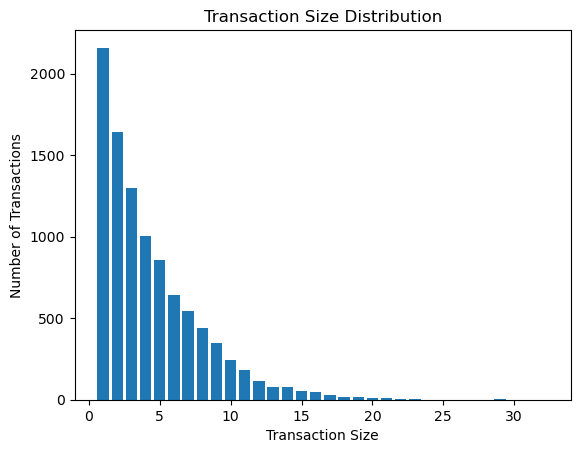

Min Support Count: 196, Min Support: 0.02

There are no frequent itemsets of size 4 or more



Frequent Itemsets:
                       Item 1                 Item 2           Item 3  Size  Counts  Support
0                  whole milk                                             1    2513  0.25552
1            other vegetables                                             1    1903  0.19349
2                  rolls/buns                                             1    1809  0.18393
3                        soda                                             1    1715  0.17438
4                      yogurt                                             1    1372  0.13950
5               bottled water                                             1    1087  0.11052
6             root vegetables                                             1    1072  0.10900
7              tropical fruit                                             1    1032  0.10493
8               shopping bags                    

In [6]:
txn_dataset = NumpyTxnItemsets('groceries')
apriori = NumpyApriori(txn_dataset, min_support=0.02, confidence_threshold=0.3)
frequent_itemsets_df = apriori.frequent_itemsets()
print()
print('Frequent Itemsets:')
print(frequent_itemsets_df)
print()
print('Association Rules with a Single Consequent:')
association_rules_df1 = apriori.association_rules(frequent_itemsets_df, 1)
print(association_rules_df1)
print()
print('Association Rules with Consequents of Size 2:')
association_rules_df2 = apriori.association_rules(frequent_itemsets_df, 2)
print(association_rules_df2 if association_rules_df2.shape[0] > 0 else 'No Such Association Rules Found')